# ĐỒ ÁN PHÂN TÍCH DỮ LIỆU
## QUY TRÌNH 3.1: PHÂN TÍCH & KIỂM ĐỊNH GIẢ THUYẾT RQ1
- **Thành viên thực hiện:** Nguyễn Thị Thanh Hằng
- **Nhiệm vụ theo phân công:**
  1. Kiểm định RQ1: Biên lợi nhuận gộp (Gross Profit Margin) có khác biệt có ý nghĩa thống kê giữa ba dòng sản phẩm hay không và dòng nào tạo ra biên cao nhất?
  2. Thống kê mô tả & trực quan hóa Boxplot GPM theo Business Line.
  3. Kiểm tra các giả định thống kê của ANOVA (Shapiro-Wilk, Levene).
  4. Thực hiện kiểm định One-way ANOVA, Kruskal-Wallis và hậu kiểm Tukey HSD.
  5. Đưa ra kết luận và đề xuất giải pháp kinh doanh.

In [ ]:
# Kết nối Google Drive nếu đang chạy trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # Chạy trên môi trường cục bộ (Jupyter Notebook / VS Code)

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, levene, f_oneway, kruskal, tukey_hsd, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Đường dẫn thư mục dữ liệu
PROCESSED = Path("DATA_PROCESS/data processed") if Path("DATA_PROCESS/data processed").exists() else Path("/content/drive/MyDrive/[LTPTDL] Đồ án/data processed")

pl_file = PROCESSED / "pl.csv"

if pl_file.exists():
    pl = pd.read_csv(pl_file)
    print("-> Đã tải thành công bảng P&L từ file:", pl_file)
else:
    # Nếu chưa có pl.csv, tích hợp từ 10 bảng đã làm sạch theo đúng quy trình 2.2 & 2.3
    FILES = ["Fact", "Calendar", "Business Line", "Group", "Subgroup", "Channel", "Region", "Headlines", "KPI", "Ratios"]
    tables = {f: pd.read_csv(PROCESSED / f"{f}.csv", dtype=str, encoding="utf-8-sig") for f in FILES}
    
    df = tables["Fact"].copy()
    calendar = tables["Calendar"].copy()
    df["Amount"] = df["Amount, $"].astype(float)
    df["Date"] = pd.to_datetime(df["Date"])
    calendar["Date"] = pd.to_datetime(calendar["Date"])
    df = df.rename(columns={"Business Line ID": "BL_ID", "Business Line Name": "BL_Name", "Subgroup ID": "Subgroup_ID", "Group ID": "Group_ID", "Revenue or expense": "RevExp"})
    
    sg = tables["Subgroup"][["Subgroup ID", "Subgroup"]].astype(str)
    gr = tables["Group"][["Group ID", "Group"]].astype(str)
    sg.columns = ["Subgroup_ID", "Subgroup_Name"]
    gr.columns = ["Group_ID", "Group_Name"]
    
    integrated = (
        df.merge(calendar[["Date", "Year", "Quarter", "Month", "Month in text"]],
                 on="Date", how="left", validate="many_to_one")
          .merge(sg, on="Subgroup_ID", how="left", validate="many_to_one")
          .merge(gr, on="Group_ID", how="left", validate="many_to_one")
    ).rename(columns={"BL_Name": "Business_Line"})
    
    data = integrated[[
        "TransactionID", "Date", "Year", "Month", "Quarter",
        "Business_Line", "Subgroup_ID", "Group_ID",
        "Amount", "Channel", "Region"
    ]].copy()
    
    data["Amount_abs"] = data["Amount"].abs()
    data["Financial_Type"] = data["Group_ID"].map({
        "1": "Revenue", "2": "Opex", "3": "COGS", "4": "Interest_Tax"
    })
    
    pl = data.pivot_table(
        index=["Month", "Quarter", "Business_Line"],
        columns="Financial_Type", values="Amount_abs",
        aggfunc="sum", fill_value=0
    ).reset_index()
    pl.columns.name = None
    
    pl["Gross_Profit"] = pl["Revenue"] - pl["COGS"]
    pl["GP_Margin"] = pl["Gross_Profit"] / pl["Revenue"]
    pl["Opex_Ratio"] = pl["Opex"] / pl["Revenue"]
    print("-> Đã tổng hợp thành công bảng P&L từ dữ liệu làm sạch!")

display(pl.head(10))

# 3. Analysis

## 3.1. RQ1 (Gross Profit Margin x Business Line)

RQ1: Biên lợi nhuận gộp (Gross Profit Margin) có khác biệt có ý nghĩa thống kê giữa ba dòng sản phẩm hay không và dòng nào tạo ra biên cao nhất?

Giả thuyết:

- H₀: Biên lợi nhuận gộp trung bình của ba dòng sản phẩm bằng nhau.
- H₁: Có ít nhất một dòng sản phẩm có GPM trung bình khác với các dòng sản phẩm còn lại.

**a. Thống kê mô tả**

In [ ]:
#Thống kê mô tả
rq1_desc = pl.groupby("Business_Line")["GP_Margin"].agg(
    n="count", mean="mean", median="median", std="std", min="min", max="max"
).round(3)
rq1_desc

,n,mean,median,std,min,max
Business_Line,,,,,,
Nutrition and Food Supplements,12,0.485,0.499,0.086,0.280,0.587
Sports equipment,12,0.600,0.611,0.078,0.407,0.694
Sportswear,12,0.709,0.698,0.044,0.655,0.790


Nhận xét: Biên lợi nhuận gộp (GPM) có sự khác biệt rõ về mặt mô tả giữa ba dòng sản phẩm (Business Line). Sportswear có GPM trung bình cao nhất và biến động thấp nhất, trong khi Nutrition and Food Supplements có GPM thấp nhất và phân tán lớn nhất.

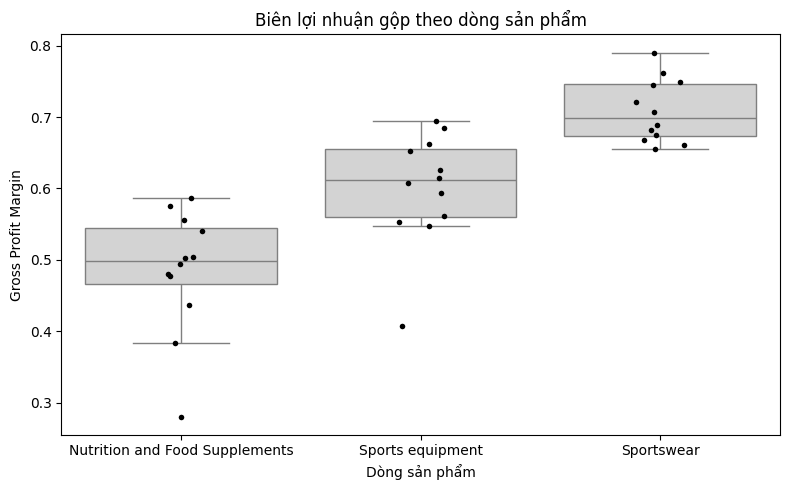

In [ ]:
#Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=pl, x="Business_Line", y="GP_Margin", color="lightgray", showfliers=False)
sns.stripplot(data=pl, x="Business_Line", y="GP_Margin", color="black", size=4)
plt.title("Biên lợi nhuận gộp theo dòng sản phẩm")
plt.xlabel("Dòng sản phẩm")
plt.ylabel("Gross Profit Margin")
plt.tight_layout()
plt.show()

Nhận xét: Boxplot cho thấy phân phối GPM giữa các nhóm có sự khác biệt, tiếp theo cần kiểm định thống kê để xác định liệu khác biệt này có ý nghĩa hay không.

**b. Kiểm định các giả định thống kê của ANOVA**

In [ ]:
from scipy.stats import shapiro, levene, f_oneway, kruskal, tukey_hsd

# 3. Kiểm tra giả định: Shapiro-Wilk (phân phối chuẩn từng nhóm), Levene (phương sai bằng nhau)
groups = {k: v["GP_Margin"].values for k, v in pl.groupby("Business_Line")}

shapiro_result = pd.Series({k: shapiro(v).pvalue for k, v in groups.items()})
print("Shapiro-Wilk p-values:")
display(shapiro_result.round(4))

print("Levene p-value:", round(levene(*groups.values()).pvalue, 4))

Shapiro-Wilk p-values:


,0
Nutrition and Food Supplements,0.1724
Sports equipment,0.1547
Sportswear,0.4008


Levene p-value: 0.5039


Nhận xét:
- Kiểm định Shapiro-Wilk: p-value của cả ba dòng sản phẩm đều lớn hơn 0,05, cho thấy biên lợi nhuận gộp của cả ba dòng sản phẩm đều không đủ bằng chứng bác bỏ giả định phân phối chuẩn.
- Kiểm định Levene: p = 0,5039 > 0,05 do đó không có bằng chứng phương sai khác nhau giữa các nhóm.

Như vậy, dữ liệu phù hợp để sử dụng One-way ANOVA. Tuy nhiên do mỗi nhóm chỉ có 12 quan sát nên nhóm sử dụng thêm kiểm định Kruskal-Wallis để đối chiếu và tăng độ tin cậy của kết quả.

**c. Kiểm định giả thuyết**

Mục đích: Sử dụng One-way ANOVA để kiểm định sự khác biệt GPM trung bình giữa ba dòng sản phẩm (Business Line), kết hợp Kruskal-Wallis để đối chiếu kết quả. Đồng thời, tính Eta bình phương (η²) nhằm đánh giá mức độ biến thiên GPM được giải thích bởi sự khác biệt giữa các dòng sản phẩm.

*One-way ANOVA và Kruskal-Wallis*

In [ ]:
# Kiểm định ANOVA và Kruskal-Wallis
f, p1 = f_oneway(*groups.values())
h, p2 = kruskal(*groups.values())

# Tính kích thước hiệu ứng Eta²
mean = pl["GP_Margin"].mean()
ss_between = sum(len(g) * (g.mean() - mean)**2 for g in groups.values())
ss_total = ((pl["GP_Margin"] - mean)**2).sum()
eta2 = ss_between / ss_total

# Kết quả (p-value viết dạng khoa học để không bị làm tròn về 0)
pd.Series({
    "ANOVA F": round(f, 2),
    "ANOVA p-value": f"{p1:.2e}",
    "Kruskal-Wallis H": round(h, 2),
    "Kruskal-Wallis p-value": f"{p2:.2e}",
    "Eta²": round(eta2, 3)
})

,0
ANOVA F,29.04
ANOVA p-value,5.31e-08
Kruskal-Wallis H,24.82
Kruskal-Wallis p-value,4.07e-06
Eta²,0.638


Nhận xét:
- Kết quả ANOVA cho F = 29,04, p < 0,001, do đó bác bỏ H₀, kết luận biên lợi nhuận gộp khác biệt có ý nghĩa thống kê giữa ba dòng sản phẩm.
- Kruskal-Wallis là kiểm định không phụ thuộc giả định phân phối chuẩn, cho kết quả H = 24,82; p < 0,001 cho thấy kết quả nhất quán giữa 2 phương pháp.
- Eta² = 0,638 cho thấy dòng sản phẩm giải thích khoảng 64% biến thiên của biên lợi nhuận gộp, thuộc mức ảnh hưởng lớn. Tuy nhiên ANOVA chỉ cho biết có sự khác biệt, chưa chỉ ra cặp nhóm nào khác nhau, nên cần hậu kiểm Tukey ở bước tiếp theo.

*Tukey HSD (Post-hoc)*

In [ ]:
# Hậu kiểm Tukey HSD: chỉ thực hiện khi ANOVA có ý nghĩa
if p1 < 0.05:
    names = list(groups.keys())
    tukey = tukey_hsd(*groups.values())

    pairs = []
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            pairs.append({
                "Cặp so sánh": f"{names[i]} vs {names[j]}",
                "p-value": f"{tukey.pvalue[i, j]:.2e}"
            })
    display(pd.DataFrame(pairs))

,Cặp so sánh,p-value
0,Nutrition and Food Supplements vs Sports equip...,1.14e-03
1,Nutrition and Food Supplements vs Sportswear,2.69e-08
2,Sports equipment vs Sportswear,2.30e-03


Nhận xét: Cả ba cặp dòng sản phẩm đều khác biệt có ý nghĩa thống kê về biên lợi nhuận gộp (p < 0,01).

**KẾT LUẬN RQ1**:
-  Kết quả kiểm định ANOVA cho thấy biên lợi nhuận gộp trung bình có sự khác biệt có ý nghĩa thống kê giữa ba dòng sản phẩm (p < 0,001).
- Kết quả hậu kiểm Tukey HSD cũng xác nhận cả ba cặp dòng sản phẩm đều có sự khác biệt có ý nghĩa thống kê. Dựa trên thống kê mô tả cho thấy Sportswear có GPM trung bình cao nhất (70,9%), tiếp đến là Sports equipment (60,0%) và thấp nhất là Nutrition and Food Supplements (48,5%).